# Wearable Sleep Data Preprocessing

This notebook demonstrates a reproducible Python workflow for cleaning and restructuring longitudinal wearable sleep and physiologic data.

The example uses a small synthetic dataset modeled on the structure of an Oura sleep export. The workflow demonstrates:

- parsing non-standard wearable data exports
- cleaning timestamps and converting measurement units
- restructuring encoded sleep-stage sequences
- extracting interval-level HRV measurements
- identifying missing and duplicate observations
- generating analysis-ready outputs

**Data note:** All data used in this demonstration are synthetically generated. No participant or protected health information is included.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# Add the project root to the Python path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.wearable_preprocessing.preprocessing import (
    read_oura_export,
    clean_oura_sleep_data,
    expand_sleep_phase,
    expand_hrv,
    summarize_missingness,
)

## 1. Load synthetic wearable data

Wearable exports can contain nested or encoded time-series fields that require restructuring before analysis. The synthetic example below reproduces several of these structural features without using research participant data.

In [2]:
raw_file = PROJECT_ROOT / "data" / "raw" / "synthetic_oura_sleep.csv"

raw = read_oura_export(raw_file)

print(f"Records: {len(raw)}")
print(f"Variables: {len(raw.columns)}")

raw.head()

Records: 3
Variables: 12


,type,bedtime_start,bedtime_end,awake_time,deep_sleep_duration,light_sleep_duration,rem_sleep_duration,total_sleep_duration,time_in_bed,sleep_phase_30_sec,sleep_phase_5_min,hrv
0,long_sleep,2026-01-01T23:00:00.000+00:00,2026-01-02T07:00:00.000+00:00,1800,5400,12600,5400,23400,28800,12341234,1234,"{""items"": [45, 50, 55], ""timestamp"": ""example""}"
1,long_sleep,2026-01-02T23:30:00.000+00:00,2026-01-03T07:15:00.000+00:00,2400,4800,12000,5100,21900,27900,123412,123,"{""items"": [60, null, 70], ""timestamp"": ""example""}"
2,rest,2026-01-03T14:00:00.000+00:00,2026-01-03T14:30:00.000+00:00,300,0,1200,0,1200,1800,1212,12,"{""items"": [52, 54], ""timestamp"": ""example""}"


## 2. Clean and standardize sleep data

The preprocessing workflow standardizes sleep-record types and timestamps and converts duration variables from seconds to minutes. These transformations produce variables that are easier to inspect and use in downstream analyses.

In [3]:
clean = clean_oura_sleep_data(raw)

columns_to_show = [
    "type",
    "bedtime_start",
    "bedtime_end",
    "total_sleep_duration",
    "awake_time",
    "time_in_bed",
]

clean[columns_to_show]

,type,bedtime_start,bedtime_end,total_sleep_duration,awake_time,time_in_bed
0,long_sleep,2026-01-01 23:00:00,2026-01-02 07:00:00,390.0,30.0,480.0
1,long_sleep,2026-01-02 23:30:00,2026-01-03 07:15:00,365.0,40.0,465.0
2,rest,2026-01-03 14:00:00,2026-01-03 14:30:00,20.0,5.0,30.0


## 3. Restructure sleep-stage sequences

Sleep-stage information may be stored as an encoded sequence rather than in an analysis-ready tabular format. The function below expands the sequence while preserving the temporal ordering of individual epochs.

In [4]:
sleep_30sec = expand_sleep_phase(
    clean,
    phase_col="sleep_phase_30_sec",
    epoch_seconds=30,
)

sleep_phase_cols = [
    col for col in sleep_30sec.columns
    if col.startswith("sleep_phase_") and col.endswith("sec")
]

sleep_30sec[
    ["type", "sleep_phase_30_sec"] + sleep_phase_cols[:8]
]

,type,sleep_phase_30_sec,sleep_phase_30_sec,sleep_phase_30sec,sleep_phase_60sec,sleep_phase_90sec,sleep_phase_120sec,sleep_phase_150sec,sleep_phase_180sec,sleep_phase_210sec
0,long_sleep,12341234,12341234,1,2,3,4,1,2,3
1,long_sleep,123412,123412,1,2,3,4,1,2,<NA>
2,rest,1212,1212,1,2,1,2,<NA>,<NA>,<NA>


## 4. Restructure HRV time series

HRV measurements can also be stored within a nested field. The preprocessing workflow extracts individual measurements into time-indexed columns while preserving missing observations in their original temporal positions.

In [5]:
hrv = expand_hrv(
    clean,
    hrv_col="hrv",
    interval_minutes=5,
)

hrv[
    [
        "type",
        "hrv_5min",
        "hrv_10min",
        "hrv_15min",
    ]
]

,type,hrv_5min,hrv_10min,hrv_15min
0,long_sleep,45,50.0,55.0
1,long_sleep,60,NaN,70.0
2,rest,52,54.0,NaN


### Example HRV time series

The expanded HRV data can be visualized across measurement intervals. Missing observations remain missing rather than shifting subsequent measurements to earlier time points.

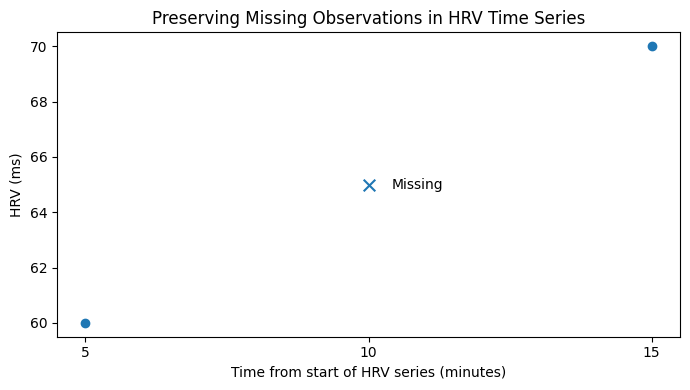

In [8]:
import matplotlib.pyplot as plt

# Select the synthetic record containing a missing
# HRV observation at the 10-minute interval
hrv_example = hrv.loc[
    1,
    ["hrv_5min", "hrv_10min", "hrv_15min"]
]

time_minutes = [5, 10, 15]
hrv_values = hrv_example.values.astype(float)

plt.figure(figsize=(7, 4))

plt.plot(
    time_minutes,
    hrv_values,
    marker="o"
)

# Mark the expected measurement interval with missing data
plt.scatter(
    [10],
    [65],
    marker="x",
    s=70,
)

plt.annotate(
    "Missing",
    xy=(10, 65),
    xytext=(10.4, 65),
    va="center",
)

plt.xlabel("Time from start of HRV series (minutes)")
plt.ylabel("HRV (ms)")
plt.title("Preserving Missing Observations in HRV Time Series")

plt.xticks(time_minutes)
plt.tight_layout()
plt.show()

## 5. Evaluate data completeness

Missingness is summarized before downstream analysis so that data availability can be evaluated explicitly rather than handled implicitly during statistical modeling.

In [7]:
missingness = summarize_missingness(clean)

missingness[
    missingness["missing_n"] > 0
].head(10)

,variable,missing_n,missing_percent


## Reproducibility

The preprocessing functions used in this notebook are implemented in `src/wearable_preprocessing/preprocessing.py`.

Automated tests evaluate sleep-stage expansion, HRV extraction, unit conversion, missingness summaries, configurable quality-control flags, and the complete raw-to-processed workflow.

All example data in this repository are synthetic.